# 01 — Data Understanding

Giai đoạn 2 của CRISP-DM: nạp dữ liệu, kiểm tra chất lượng, lập data
dictionary, và khám phá (EDA) các đặc điểm chính của điểm thi THPT 2026.

Toàn bộ logic xử lý nằm trong `src/preprocessing.py` và
`src/visualization.py`; notebook này chỉ gọi hàm và trình bày kết quả.
Xem `reports/data_dictionary.md` và `reports/decisions_log.md` (DEC-004,
DEC-005) để biết các quyết định rút ra từ phân tích này.

In [1]:
import sys
sys.path.insert(0, "..")

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.preprocessing import (
    load_raw_csv, check_sbd_consistency, check_duplicate_sbd,
    check_score_range, check_score_step, n_subjects_taken,
    SUBJECT_COLUMNS, ELECTIVE_SUBJECTS, COMPULSORY_SUBJECTS,
)
from src.visualization import save_fig, plot_score_distribution

pd.set_option("display.max_columns", 50)

## 2.1 Nạp dữ liệu và kiểm tra kích thước/kiểu dữ liệu

In [2]:
df = load_raw_csv("../data/raw/diem_thi_2026.csv")
print("Số dòng:", f"{len(df):,}")
print("Số cột:", df.shape[1])
print(f"Bộ nhớ: {df.memory_usage(deep=True).sum()/1e6:.1f} MB")
df.dtypes

Số dòng: 1,208,863
Số cột: 27
Bộ nhớ: 133.0 MB


sbd                        string
nam                         int16
province_code               int16
sbd_seq                     int32
toan                      float32
ngu_van                   float32
vat_ly                    float32
hoa_hoc                   float32
sinh_hoc                  float32
lich_su                   float32
dia_ly                    float32
kinh_te_phap_luat         float32
tin_hoc                   float32
cong_nghe_cong_nghiep     float32
cong_nghe_nong_nghiep     float32
ngoai_ngu                 float32
ma_mon_ngoai_ngu         category
tong_diem                 float32
khoi_a                    float32
khoi_a1                   float32
khoi_b                    float32
khoi_c                    float32
khoi_d                    float32
khoi_a02                  float32
khoi_c01                  float32
khoi_d07                  float32
province_name            category
dtype: object

## 2.2 Kiểm tra chất lượng dữ liệu

Kiểm tra 4 loại vấn đề: cấu trúc SBD không nhất quán, SBD trùng lặp,
điểm ngoài khoảng [0, 10], và lưới bước điểm 0,25 (để xác nhận/bác bỏ
giả định ban đầu).

In [3]:
ok = check_sbd_consistency(df)
print("Dòng SBD không khớp province_code + sbd_seq:", (~ok).sum())

dup = check_duplicate_sbd(df)
print("Dòng SBD trùng lặp:", len(dup))

bad_range = check_score_range(df)
print("Dòng có điểm ngoài [0, 10]:", len(bad_range))

Dòng SBD không khớp province_code + sbd_seq: 0
Dòng SBD trùng lặp: 0
Dòng có điểm ngoài [0, 10]: 0


In [4]:
# Kiểm tra bước điểm 0,25 cho từng môn — xem DEC-004: giả định "0,25 cố
# định" chỉ đúng với Ngữ văn, các môn khác có câu đúng/sai chấm điểm mịn hơn.
step_report = {}
for col in SUBJECT_COLUMNS:
    vals = df[col].dropna()
    if len(vals) == 0:
        continue
    off = check_score_step(df, columns=[col])
    step_report[col] = 100 * len(off) / len(vals)

pd.Series(step_report, name="% lệch lưới 0,25").sort_values(ascending=False).round(2)

kinh_te_phap_luat        52.93
dia_ly                   37.41
lich_su                  34.26
sinh_hoc                 32.97
tin_hoc                  31.81
cong_nghe_cong_nghiep    31.06
vat_ly                   26.67
hoa_hoc                  26.19
toan                     14.21
cong_nghe_nong_nghiep    12.92
ngu_van                   0.41
ngoai_ngu                 0.00
Name: % lệch lưới 0,25, dtype: float64

**Kết luận:** 0 dòng lệch cấu trúc SBD, 0 dòng trùng SBD, 0 dòng điểm
ngoài khoảng hợp lệ — dữ liệu đã được người thu thập làm sạch tốt ở các
khía cạnh này. Về bước điểm, chỉ Ngữ văn bám sát lưới 0,25 (<1% lệch);
các môn khác lệch 14–99% do định dạng đề thi 2026 có câu hỏi đúng/sai
chấm theo số ý đúng (0,1/0,25/0,5/1 điểm). Quyết định: không lọc "lệch
lưới 0,25" như một lỗi dữ liệu (xem DEC-004).

## 2.3 Phân biệt "không thi môn" và "thiếu dữ liệu"

In [5]:
ns = n_subjects_taken(df)
print("Phân bố số môn đã thi / thí sinh:")
print(ns.value_counts().sort_index())

missing_toan = df["toan"].isna().sum()
missing_van = df["ngu_van"].isna().sum()
missing_both = (df["toan"].isna() & df["ngu_van"].isna()).sum()
print(f"\nThiếu Toán (bắt buộc): {missing_toan:,} ({100*missing_toan/len(df):.2f}%)")
print(f"Thiếu Ngữ văn (bắt buộc): {missing_van:,} ({100*missing_van/len(df):.2f}%)")
print(f"Thiếu cả hai: {missing_both:,}")

Phân bố số môn đã thi / thí sinh:
1       1715
2       1182
3      40384
4    1165582
Name: count, dtype: int64

Thiếu Toán (bắt buộc): 16,426 (1.36%)
Thiếu Ngữ văn (bắt buộc): 11,636 (0.96%)
Thiếu cả hai: 72


In [6]:
# Xác nhận: trong nhóm thi đủ 4 môn, có đúng 2 môn tự chọn không?
mask4 = ns == 4
elective_count = df.loc[mask4, ELECTIVE_SUBJECTS].notna().sum(axis=1)
print("Trong nhóm thi đủ 4 môn, số môn tự chọn đã thi:")
print(elective_count.value_counts())

Trong nhóm thi đủ 4 môn, số môn tự chọn đã thi:
2    1165582
Name: count, dtype: int64


**Kết luận:** 96,42% thí sinh thi đúng 4 môn (2 bắt buộc + 2 tự chọn)
như quy chế chuẩn — xác nhận giá trị trống ở các môn tự chọn là "không
đăng ký thi", không phải thiếu dữ liệu. Phần thiểu số (3,58%) thiếu môn
bắt buộc hoặc thi không đủ 4 môn được xử lý riêng ở GIAI ĐOẠN 3 (xem
DEC-005).

## 2.4 Thống kê theo tỉnh/thành

In [7]:
province_counts = df["province_name"].value_counts()
print(f"Số tỉnh: {province_counts.shape[0]}")
print(f"Tỉnh đông nhất: {province_counts.index[0]} ({province_counts.iloc[0]:,} thí sinh)")
print(f"Tỉnh ít nhất: {province_counts.index[-1]} ({province_counts.iloc[-1]:,} thí sinh)")
province_counts

Số tỉnh: 34
Tỉnh đông nhất: Hồ Chí Minh (139,678 thí sinh)
Tỉnh ít nhất: Lai Châu (4,650 thí sinh)


province_name
Hồ Chí Minh    139678
Hà Nội         126867
Hải Phòng       56819
Đồng Nai        52568
Ninh Bình       48238
Phú Thọ         47668
Bắc Ninh        43812
Hưng Yên        43232
Thanh Hóa       42429
Nghệ An         41676
Lâm Đồng        40985
An Giang        39861
Gia Lai         37378
Đồng Tháp       37027
Vĩnh Long       36320
Đà Nẵng         35526
Đắk Lắk         35280
Cần Thơ         34071
Tây Ninh        29035
Thái Nguyên     22582
Khánh Hòa       21874
Quảng Trị       21568
Quảng Ngãi      21481
Quảng Ninh      20591
Lào Cai         19715
Cà Mau          19534
Hà Tĩnh         18487
Tuyên Quang     18050
Sơn La          14162
Huế             14087
Lạng Sơn        10058
Điện Biên        7947
Cao Bằng         5607
Lai Châu         4650
Name: count, dtype: int64

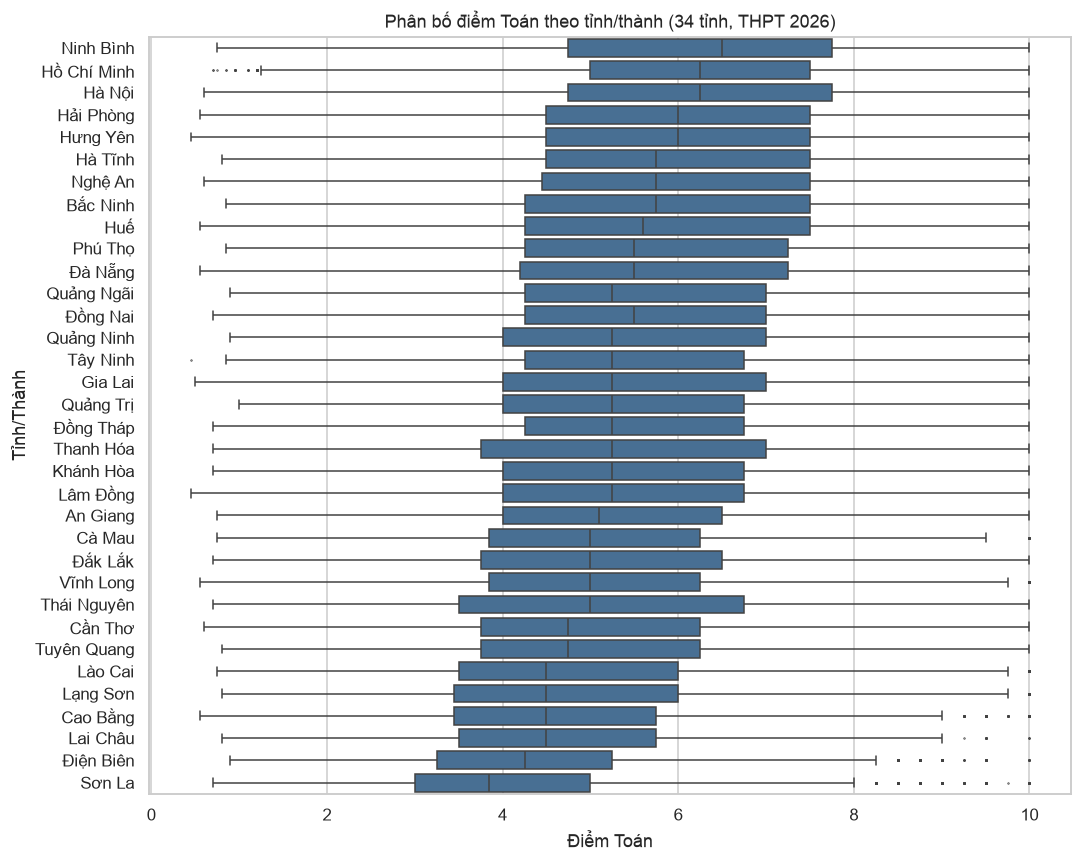

In [8]:
fig, ax = plt.subplots(figsize=(10, 8))
order = df.groupby("province_name", observed=True)["toan"].mean().sort_values(ascending=False).index
sns.boxplot(data=df, y="province_name", x="toan", order=order, ax=ax, color="#3b6fa0", fliersize=0.5)
ax.set_xlabel("Điểm Toán")
ax.set_ylabel("Tỉnh/Thành")
ax.set_title("Phân bố điểm Toán theo tỉnh/thành (34 tỉnh, THPT 2026)")
save_fig(fig, "02_diem_toan_theo_tinh")
plt.show()

## 2.5 Phổ điểm các môn bắt buộc

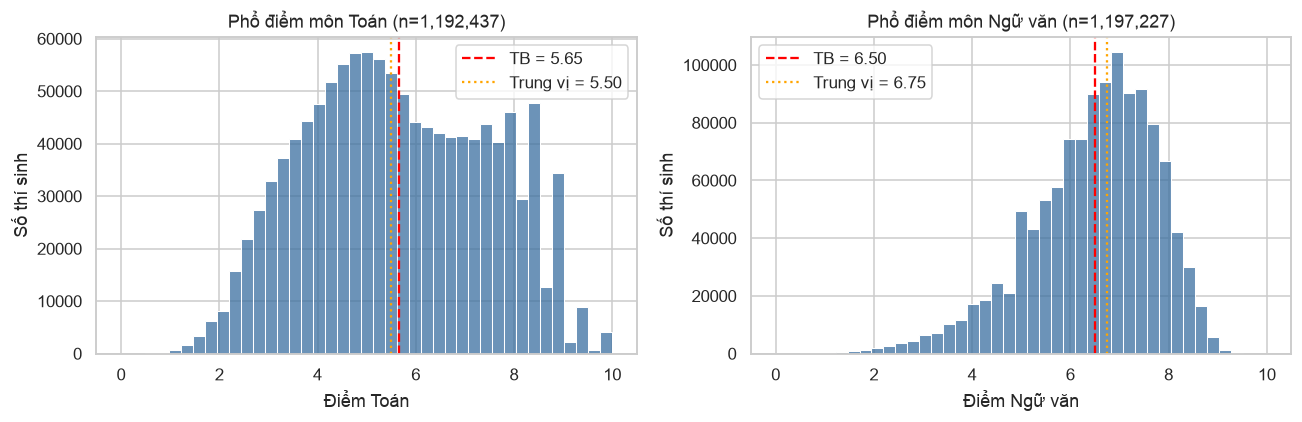

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
plot_score_distribution(df, "toan", "Toán", ax=axes[0])
plot_score_distribution(df, "ngu_van", "Ngữ văn", ax=axes[1])
save_fig(fig, "02_pho_diem_toan_van")
plt.show()

## 2.6 Ma trận tương quan giữa các môn

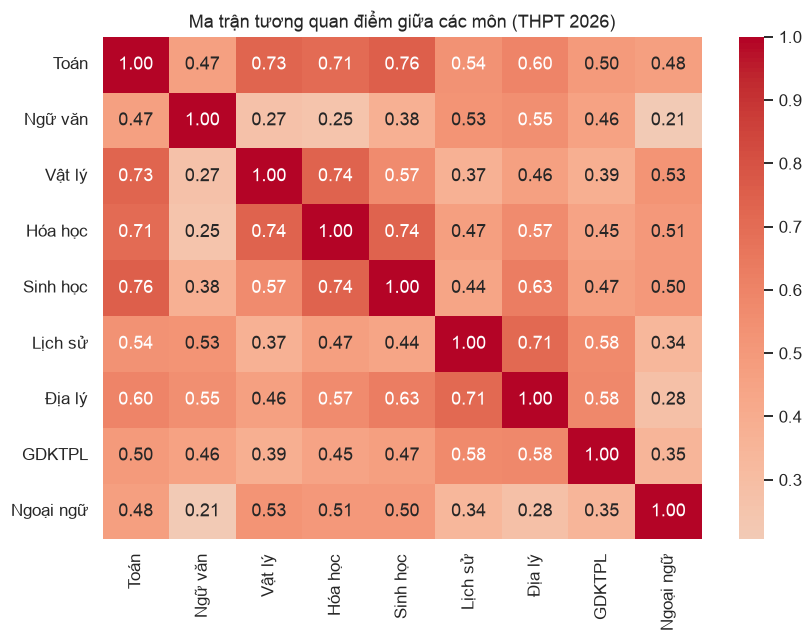

In [10]:
cols = ["toan", "ngu_van", "vat_ly", "hoa_hoc", "sinh_hoc", "lich_su", "dia_ly", "kinh_te_phap_luat", "ngoai_ngu"]
labels = ["Toán", "Ngữ văn", "Vật lý", "Hóa học", "Sinh học", "Lịch sử", "Địa lý", "GDKTPL", "Ngoại ngữ"]
corr = df[cols].corr()
corr.index = labels
corr.columns = labels

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax)
ax.set_title("Ma trận tương quan điểm giữa các môn (THPT 2026)")
save_fig(fig, "02_ma_tran_tuong_quan")
plt.show()

Toán tương quan mạnh với khối Tự nhiên (Sinh 0,76; Vật lý 0,73; Hóa
0,71); Ngữ văn tương quan mạnh với khối Xã hội (Địa lý 0,55; Lịch sử
0,53) — phù hợp trực giác sư phạm. Dùng làm đường cơ sở để diễn giải
luật kết hợp ở GIAI ĐOẠN 4: luật trùng với tương quan tuyến tính là dự
đoán được, luật *lệch* khỏi xu hướng này mới thực sự đáng chú ý.

## 2.7 Tỷ lệ chọn tổ hợp môn tự chọn

In [11]:
mask2 = df[ELECTIVE_SUBJECTS].notna().sum(axis=1) == 2
name_map = {
    "vat_ly": "Vật lý", "hoa_hoc": "Hóa học", "sinh_hoc": "Sinh học",
    "lich_su": "Lịch sử", "dia_ly": "Địa lý", "kinh_te_phap_luat": "GDKTPL",
    "tin_hoc": "Tin học", "cong_nghe_cong_nghiep": "CN Công nghiệp",
    "cong_nghe_nong_nghiep": "CN Nông nghiệp", "ngoai_ngu": "Ngoại ngữ",
}
combo = df.loc[mask2, ELECTIVE_SUBJECTS].notna().apply(
    lambda r: " + ".join(name_map[c] for c in ELECTIVE_SUBJECTS if r[c]), axis=1
)
top10 = combo.value_counts().head(10)
print(f"Số thí sinh thi đúng 2 môn tự chọn: {mask2.sum():,}")
top10

Số thí sinh thi đúng 2 môn tự chọn: 1,191,271


Lịch sử + Địa lý       277309
Vật lý + Hóa học       175249
Vật lý + Ngoại ngữ     144311
Lịch sử + GDKTPL       120475
Địa lý + GDKTPL        103374
Lịch sử + Ngoại ngữ     89155
Hóa học + Sinh học      47203
Địa lý + Ngoại ngữ      46114
Vật lý + Lịch sử        36337
GDKTPL + Ngoại ngữ      34251
Name: count, dtype: int64

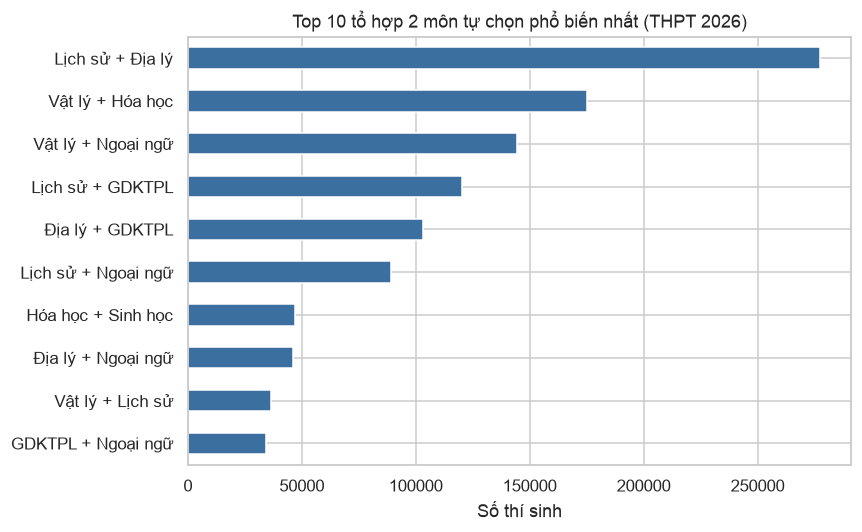

In [12]:
fig, ax = plt.subplots(figsize=(8, 5))
top10.sort_values().plot(kind="barh", ax=ax, color="#3b6fa0")
ax.set_xlabel("Số thí sinh")
ax.set_title("Top 10 tổ hợp 2 môn tự chọn phổ biến nhất (THPT 2026)")
save_fig(fig, "02_top_to_hop_tu_chon")
plt.show()

Địa lý + Lịch sử (277.309 thí sinh) và Hóa học + Vật lý (175.249) là
hai tổ hợp phổ biến nhất — phản ánh rõ ranh giới truyền thống giữa khối
Khoa học Xã hội và Khoa học Tự nhiên, dù chương trình 2018 cho phép chọn
tự do. Đây là tín hiệu quan trọng cho GIAI ĐOẠN 4.1 (luật kết hợp).

## 2.8 Đối chiếu hiện tượng dồn điểm Ngữ văn tại 5,0

In [13]:
counts = df["ngu_van"].value_counts().sort_index()
neighbors = (counts.get(4.75, 0) + counts.get(5.25, 0)) / 2
spike = counts.get(5.0, 0)
print(f"Số thí sinh đạt đúng 5,0 điểm Văn: {spike:,}")
print(f"Trung bình nội suy từ điểm lân cận (4,75 & 5,25): {neighbors:,.1f}")
print(f"Tỷ lệ dôi ra: {spike/neighbors:.2f}x")

Số thí sinh đạt đúng 5,0 điểm Văn: 49,195
Trung bình nội suy từ điểm lân cận (4,75 & 5,25): 31,851.5
Tỷ lệ dôi ra: 1.54x


Tỷ lệ 1,54× khớp với quan sát đã công bố trong README của repo dữ liệu
gốc (ước tính ~1,5× toàn quốc). Đây là cơ sở để thực hiện kiểm định
heaping chính thức (so sánh với phân phối kỳ vọng, theo tỉnh) ở GIAI
ĐOẠN 4.3 — **chỉ coi là tín hiệu thống kê cần xem xét thêm, không kết
luận nguyên nhân.**

## 2.9 Tóm tắt phát hiện chính (đưa sang GIAI ĐOẠN 3-4)

1. Dữ liệu sạch về cấu trúc (SBD, khoảng điểm) — không cần xử lý lỗi kỹ thuật.
2. Bước điểm 0,25 chỉ đúng với Ngữ văn — ảnh hưởng cách rời rạc hóa điểm ở GIAI ĐOẠN 3 (DEC-004).
3. ~3,6% thí sinh thiếu môn bắt buộc hoặc thi không đủ 4 môn — loại khỏi bảng giao dịch luật kết hợp, giữ lại ở bảng đặc trưng tỉnh/điểm thi (DEC-005).
4. Tương quan giữa các môn có cấu trúc rõ (Tự nhiên vs Xã hội) — dùng làm đường cơ sở diễn giải luật kết hợp.
5. Tổ hợp Địa lý+Lịch sử và Hóa+Lý chiếm ưu thế — gợi ý luật kết hợp sẽ phản ánh rõ 2 nhóm truyền thống.
6. Xác nhận hiện tượng dồn điểm Văn=5,0 (1,54× kỳ vọng) — đưa vào GIAI ĐOẠN 4.3 kiểm định chính thức.